In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [34]:
from sklearn.datasets import load_diabetes

data = load_diabetes()

In [35]:
X = data.data
y = data.target

In [36]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=45)

In [37]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [38]:
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

from sklearn.metrics import r2_score, mean_squared_error

print("R2 Score", r2_score(y_test,y_pred))
print("RMSE", np.sqrt(mean_squared_error(y_test,y_pred)))

R2 Score 0.5188113124539249
RMSE 48.72713760953253


In [39]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=0.001)
ridge.fit(X_train,y_train)
y_pred = ridge.predict(X_test)

print("R2 Score", r2_score(y_test,y_pred))
print("RMSE", np.sqrt(mean_squared_error(y_test,y_pred)))


R2 Score 0.5201448351821762
RMSE 48.65957177859253


In [40]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np

X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)


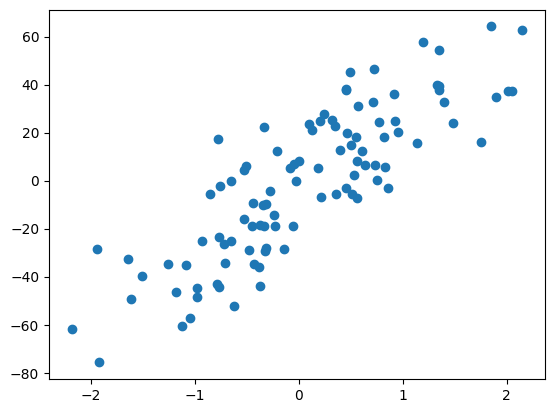

In [41]:
plt.scatter(X,y)


In [42]:
lr = LinearRegression()
lr.fit(X,y)
print(lr.coef_)
print(lr.intercept_)

[27.82809103]
-2.29474455867698


In [43]:
rr = Ridge(alpha=10)
rr.fit(X,y)
print(rr.coef_)
print(rr.intercept_)

[24.9546267]
-2.1269130035235735


In [44]:
rr1 = Ridge(alpha=10)
rr1.fit(X,y)
print(rr1.coef_)
print(rr1.intercept_)

[24.9546267]
-2.1269130035235735


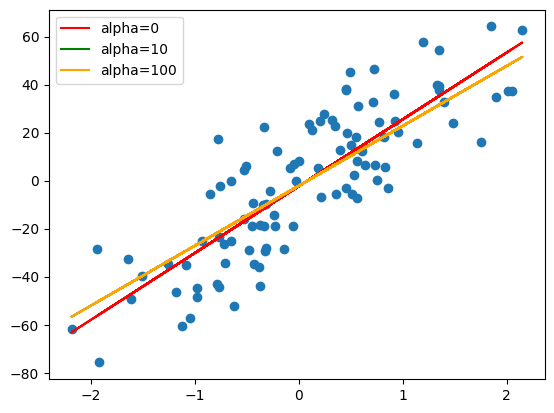

In [45]:
plt.scatter(X,y)
plt.plot(X,lr.predict(X), color='red',label="alpha=0")
plt.plot(X,rr.predict(X), color='green',label="alpha=10")
plt.plot(X,rr1.predict(X), color='orange',label="alpha=100")

plt.legend()

plt.show()

## Ridge Regression (Least Square)

In [48]:
X,y = load_diabetes(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=4)
reg = Ridge(alpha=0.1,solver='cholesky')
reg.fit(X_train,y_train)
y_pred = reg.predict(X_test)
R2_score = r2_score(y_test,y_pred)


print(R2_score)
print(reg.coef_)
print(reg.intercept_)

0.4693128853309805
[  44.02063391 -241.69329987  452.98665299  332.04420177  -76.33686744
  -68.52143809 -164.98809083  149.96908118  431.61347417   58.51862681]
150.89053425602808


## Ridge Regression from Scratch (Least Square)

In [57]:
class OurRidge:
  def __init__(self,alpha=0.1):
    self.alpha = alpha
    self.coef_ = None
    self.intercept_ = None

  def fit(self,X_train,y_train):
    X_train = np.insert(X_train,0,1,axis=1)
    I = np.identity(X_train.shape[1])
    I[0][0] = 0
    result = np.linalg.inv(np.dot(X_train.T,X_train) + self.alpha * I).dot(X_train.T).dot(y_train)
    self.intercept_ = result[0]
    self.coef_ = result[1:]

  def predict(self,X_test):
    return np.dot(X_test,self.coef_) + self.intercept_

In [58]:
X_train.shape

(353, 10)

In [59]:
np.insert(X_train,0,1,axis=1).shape

(353, 11)

In [60]:
reg = OurRidge()
reg.fit(X_train,y_train)
y_pred = reg.predict(X_test)
print(r2_score(y_test,y_pred))
print(reg.coef_)
print(reg.intercept_)

0.4693128853309805
[  44.02063391 -241.69329987  452.98665299  332.04420177  -76.33686744
  -68.52143809 -164.98809083  149.96908118  431.61347417   58.51862681]
150.8905342560281


## Ridge Regression using Gradient Descent

In [64]:
from sklearn.linear_model import SGDRegressor

reg = SGDRegressor(penalty='l2',max_iter=500,eta0=0.1,learning_rate='constant',alpha=0.001)

reg.fit(X_train,y_train)
y_pred = reg.predict(X_test)
print("R2 Score",r2_score(y_test,y_pred))
print(reg.coef_)
print(reg.intercept_)

R2 Score 0.4485519115634149
[  56.83794756 -137.66052044  353.01853925  259.55149572    2.72421966
  -47.58805428 -170.85901449  141.42396757  318.760826    103.5043824 ]
[162.21825446]


In [65]:
reg = Ridge(alpha=0.001, max_iter=500,solver='sparse_cg')

# solver : sparse_cg use Gradient descent


reg.fit(X_train,y_train)
y_pred = reg.predict(X_test)
print("R2 Score",r2_score(y_test,y_pred))
print(reg.coef_)
print(reg.intercept_)

R2 Score 0.46250101619914563
[  34.52192544 -290.84084076  482.40181344  368.0678662  -852.44873179
  501.59160336  180.11115788  270.76333979  759.73534372   37.4913546 ]
151.10198517439466
